In [ ]:
import pandas as pd
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt
from tqdm import tqdm
import kagglehub


# filtering

BASE_DIR = r"C:\Users\arnav\.cache\kagglehub\datasets\andrewmvd\ocular-disease-recognition-odir5k\versions\2"
IMG_DIR = os.path.join(BASE_DIR, "preprocessed_images") 
CSV_PATH = os.path.join(BASE_DIR, "full_df.csv")

df = pd.read_csv(CSV_PATH)
data = []

for _, row in df.iterrows():
    if row['H'] == 1:
        label = 'Hypertension'
        is_mixed = row[['D','G','C','A','M','O']].sum() > 0
    elif row['N'] == 1:
        label = 'Normal'
        is_mixed = False
    else:
        continue


    # Process Both Eyes
    for side, filename_col in [('Left', 'Left-Fundus'), ('Right', 'Right-Fundus')]:
        filepath = os.path.join(IMG_DIR, row[filename_col])

        # Only add if file exists
        if os.path.exists(filepath):
            data.append({
                'Patient_ID': row['ID'],
                'filename': row[filename_col],
                'filepath': filepath,
                'label': label,
                'is_mixed': is_mixed, # True if they have comorbidities
                'age': row['Patient Age']
            })


df_audit = pd.DataFrame(data)
print(f"Total Images for Analysis: {len(df_audit)}")
print(df_audit['label'].value_counts())



d:\Large Group Project\Project-Retinexis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Total Images for Analysis: 4546
label
Normal          4143
Hypertension     403
Name: count, dtype: int64


In [2]:
# stage 1 - physical audit
# check for resolution, black border and green channel

widths = []
heights = []
fill_factors = []
green_vars = []
blur_scores = []

for idx, row in tqdm(df_audit.iterrows(), total=len(df_audit)):
    img = cv2.imread(row['filepath'])

    if img is None:
        widths.append(0); heights.append(0); fill_factors.append(0); green_vars.append(0)
        continue 

    # resolution
    h, w, _ = img.shape
    widths.append(w)
    heights.append(h)


    # black border analysis
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(gray, cv2.COLOR_RGB2GRAY)
    tissue_pixels = np.count_nonzero(gray > 10)
    total_pixels = h * w
    fill_factors.append(tissue_pixels / total_pixels)

    
    # green channel variance
    green_channel = img[:, :, 1]
    green_vars.append(np.std(green_channel))

    laplacian_var = cv2.Laplacian(gray, cv2.CV_64F).var()
    blur_scores.append(laplacian_var)


df_audit['width'] = widths
df_audit['heights'] = heights
df_audit['fill_factor'] = fill_factors
df_audit['green_std'] = green_vars
df_audit['blur_score'] = blur_scores






  0%|          | 0/4546 [00:00<?, ?it/s]

100%|██████████| 4546/4546 [00:16<00:00, 275.96it/s]


C:\Users\arnav\AppData\Local\Temp\ipykernel_1636\3492987520.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_audit, x='label', y='fill_factor', ax=axes[1], palette={'Normal':'green', 'Hypertension':'red'})
C:\Users\arnav\AppData\Local\Temp\ipykernel_1636\3492987520.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_audit, x='label', y='green_std', ax=axes[2], palette={'Normal':'green', 'Hypertension':'red'})


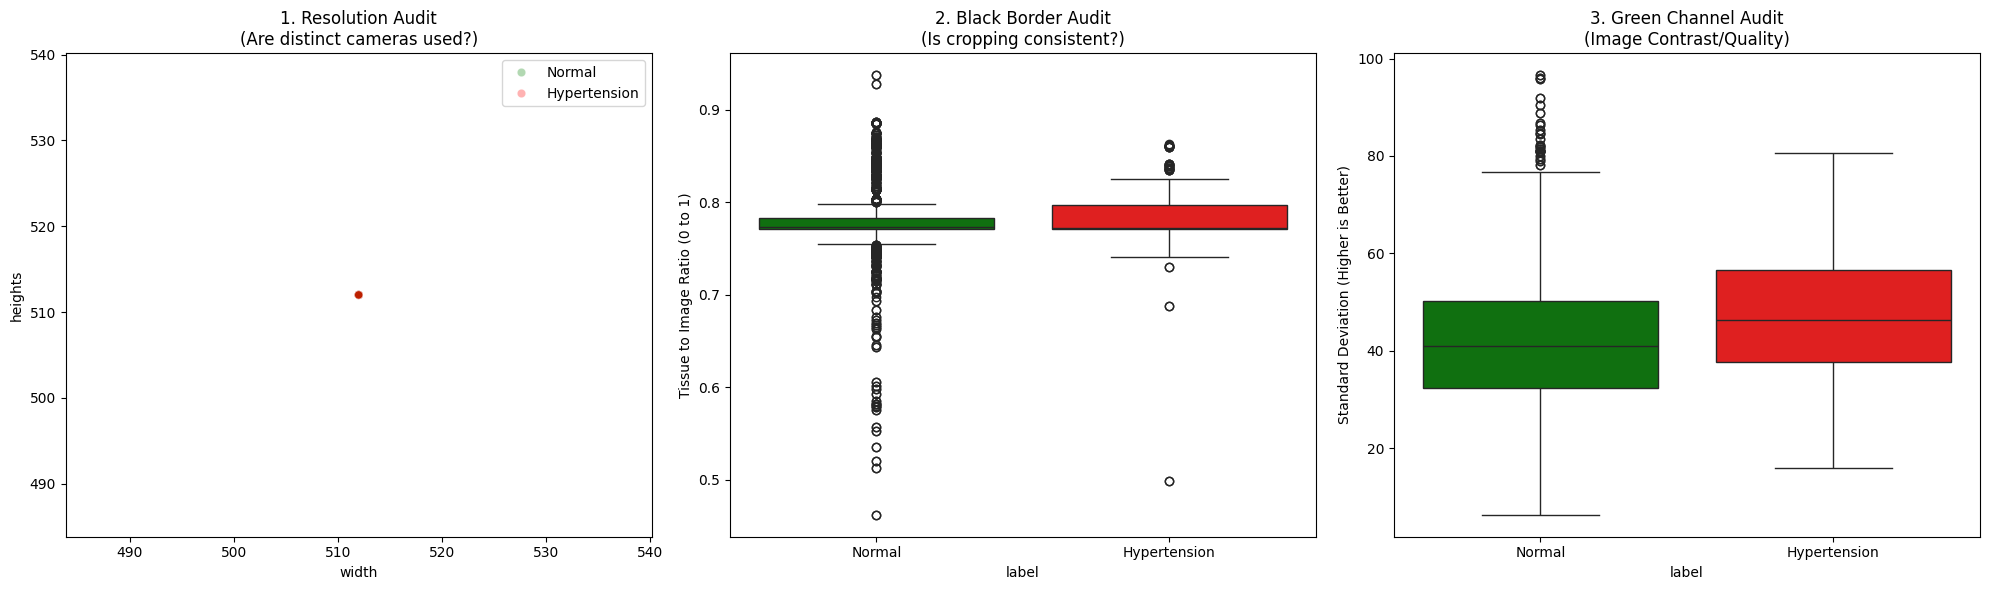

C:\Users\arnav\AppData\Local\Temp\ipykernel_1636\3492987520.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_audit, x='label', y='blur_score', palette={'Normal':'green', 'Hypertension':'red'})


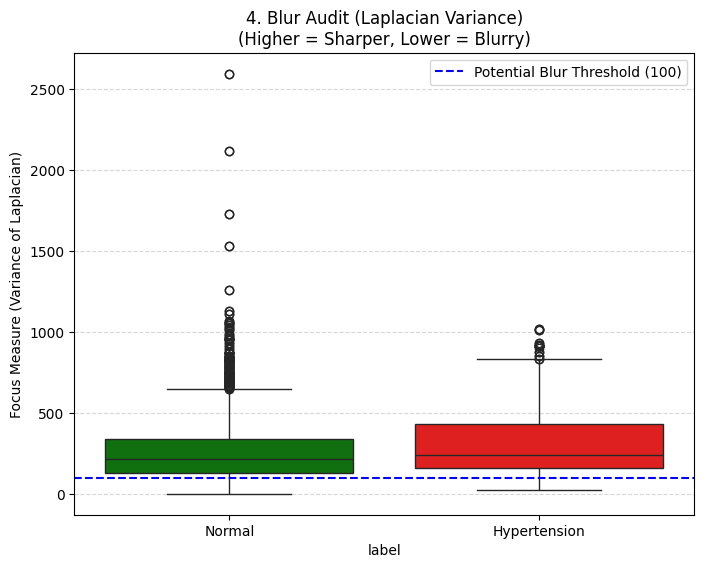


1. Camera Consistency: Found 1 different image resolutions.
   width  heights  count
0    512      512   4546

2. Image Quality (Green Variance):
   Normal Avg: 42.09
   Hypertension Avg: 46.89
   ✅ PASS: Image quality is comparable.


In [3]:
# visualisation

import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# width vs height
sns.scatterplot(data=df_audit, x='width', y='heights', hue='label', alpha=0.3, ax=axes[0], palette={'Normal':'green', 'Hypertension':'red'})
axes[0].set_title("1. Resolution Audit\n(Are distinct cameras used?)")
axes[0].legend(loc='upper right')


# black border analysis
sns.boxplot(data=df_audit, x='label', y='fill_factor', ax=axes[1], palette={'Normal':'green', 'Hypertension':'red'})
axes[1].set_title("2. Black Border Audit\n(Is cropping consistent?)")
axes[1].set_ylabel("Tissue to Image Ratio (0 to 1)")


# green channel variance
sns.boxplot(data=df_audit, x='label', y='green_std', ax=axes[2], palette={'Normal':'green', 'Hypertension':'red'})
axes[2].set_title("3. Green Channel Audit\n(Image Contrast/Quality)")
axes[2].set_ylabel("Standard Deviation (Higher is Better)")

plt.tight_layout()
plt.show()

# blur

plt.figure(figsize=(8, 6))

# Plot the Blur Score
sns.boxplot(data=df_audit, x='label', y='blur_score', palette={'Normal':'green', 'Hypertension':'red'})

plt.title("4. Blur Audit (Laplacian Variance)\n(Higher = Sharper, Lower = Blurry)")
plt.ylabel("Focus Measure (Variance of Laplacian)")
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add a reference line for "Too Blurry"
# Note: This threshold varies by dataset, but <100 is often a good starting point for finding garbage.
plt.axhline(y=100, color='blue', linestyle='--', label='Potential Blur Threshold (100)')
plt.legend()

plt.show()



# summary
unique_sizes = df_audit.groupby(['width', 'heights']).size().reset_index(name='count')
print(f"\n1. Camera Consistency: Found {len(unique_sizes)} different image resolutions.")
print(unique_sizes.sort_values('count', ascending=False).head(3))

# green channel difference
mean_norm_g = df_audit[df_audit['label']=='Normal']['green_std'].mean()
mean_hyper_g = df_audit[df_audit['label']=='Hypertension']['green_std'].mean()
print(f"\n2. Image Quality (Green Variance):")
print(f"   Normal Avg: {mean_norm_g:.2f}")
print(f"   Hypertension Avg: {mean_hyper_g:.2f}")
if abs(mean_norm_g - mean_hyper_g) > 5:
    print("   ⚠️ FLAG: Significant quality difference detected between classes.")
else:
    print("   ✅ PASS: Image quality is comparable.")








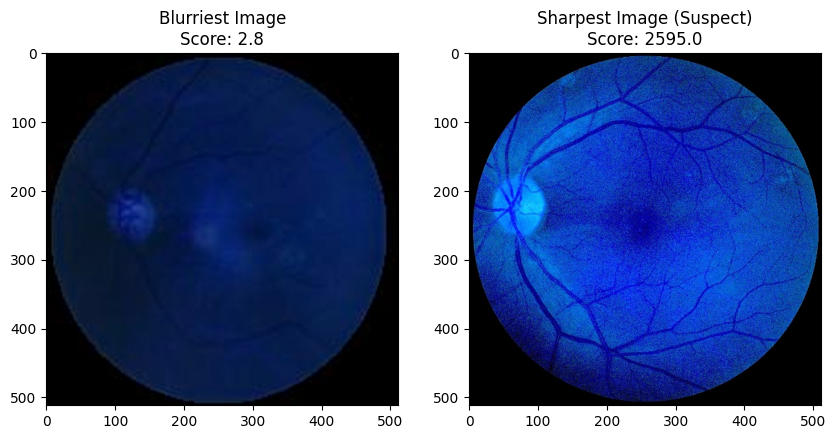

In [5]:
# blur detection

# 1. Get the indices of the extremes
worst_blur_idx = df_audit['blur_score'].idxmin() # The blurriest image
weirdest_sharp_idx = df_audit['blur_score'].idxmax() # The sharpest image (likely artifact)

# 2. Load them
img_blur = cv2.imread(df_audit.loc[worst_blur_idx, 'filepath'])
img_sharp = cv2.imread(df_audit.loc[weirdest_sharp_idx, 'filepath'])

# 3. Show them
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(img_blur)
ax[0].set_title(f"Blurriest Image\nScore: {df_audit.loc[worst_blur_idx, 'blur_score']:.1f}")

ax[1].imshow(img_sharp)
ax[1].set_title(f"Sharpest Image (Suspect)\nScore: {df_audit.loc[weirdest_sharp_idx, 'blur_score']:.1f}")

plt.show()


In [9]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(test_size=0.20, n_splits=1, random_state=42)

split = splitter.split(df_audit, groups=df_audit['Patient_ID'])
train_inds, test_inds = next(split)

train_df_audit = df_audit.iloc[train_inds].copy()
test_df_audit = df_audit.iloc[test_inds].copy()

train_patients = set(train_df_audit['Patient_ID'])
test_patients = set(test_df_audit['Patient_ID'])
overlap = train_patients.intersection(test_patients)

assert len(overlap) == 0, f"CRITICAL FAILURE: Found {len(overlap)} patients in both sets!"
print(f"✅ Success! Split complete.")
print(f"   Train Patients: {len(train_patients)} | Train Images: {len(train_df_audit)}")
print(f"   Test Patients:  {len(test_patients)} | Test Images:  {len(test_df_audit)}")


✅ Success! Split complete.
   Train Patients: 946 | Train Images: 3628
   Test Patients:  237 | Test Images:  918


In [ ]:
def check_laterality(filepath, label_side):
    """
    Returns True if the bright spot matches the label (Left/Right).
    Returns False if they disagree.
    """

    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        return False
    
  
    img_blur = cv2.GaussianBlur(img, (21, 21), 0)


    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(img_blur)
    bright_x = max_loc[0]
    width = img.shape[1]
    

    detected_side = 'Left' if bright_x > (width / 2) else 'Right'
    
    
    if label_side in ['Left', 'Left-Fundus']:
        return detected_side == 'Left'
    elif label_side in ['Right', 'Right-Fundus']:
        return detected_side == 'Right'
    
    return True

mismatches = []

for idx, row in tqdm(df_audit.iterrows(), total=len(df_audit)):
  
    side_label = 'Left' if 'Left' in row['filename'] else 'Right'
    
    if not check_laterality(row['filepath'], side_label):
        mismatches.append(idx)

print(f"\n🔍 Check Complete.")
print(f"   Total Mismatches Found: {len(mismatches)}")


if len(mismatches) > 0:
    print("   ⚠️ WARNING: The following images might be labeled wrong (or inverted):")
    print(df_audit.loc[mismatches, ['Patient_ID', 'filename']])



100%|██████████| 4546/4546 [00:05<00:00, 838.68it/s]


🔍 Check Complete.
   Total Mismatches Found: 2330
   ⚠️ WARNING: The following images might be labeled wrong (or inverted):
      Patient_ID        filename
1              1     1_right.jpg
3              8     8_right.jpg
4             11     11_left.jpg
5             11    11_right.jpg
7             23    23_right.jpg
...          ...             ...
4535        4579  4579_right.jpg
4537        4581  4581_right.jpg
4539        4591  4591_right.jpg
4541        4592  4592_right.jpg
4543        4637  4637_right.jpg

[2330 rows x 2 columns]


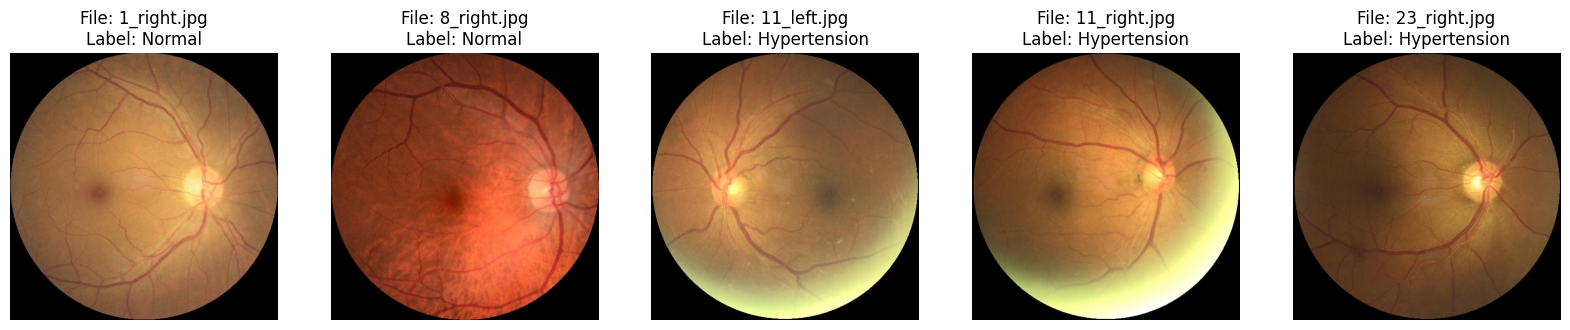

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, idx in enumerate(mismatches[:5]):
    row = df_audit.loc[idx]
    img = cv2.imread(row['filepath'])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) 
    axes[i].imshow(img)
    axes[i].set_title(f"File: {row['filename']}\nLabel: {row['label']}")
    axes[i].axis('off')
plt.show()